# AGC en lazo cerrado con el loopback DAC → ADC (sin el ADRF)

Prueba el **registro por ráfaga de la FPGA** (`gmsk_pico_rafaga`) y la **lógica del AGC por eventos** con el bitstream de pruebas (TX por DDR) y `adc_server_nivel`. Como no hay ADRF, la ganancia se emula con la amplitud del TX:
el nivel de cada barco a 0 dB de ganancia es `p_in` (dBFS en el ADC), el AGC elige una ganancia `g` y el TX transmite con amplitud `A = 8191 · 10^((p_in + g)/20)` (se recorta en 8191 = 0 dBFS, como el ADC al saturar).
La FPGA mide el nivel y demodula esa señal de verdad: lo que se prueba es que, con los niveles que elige el AGC, **las ráfagas demodulan** (CRC correcto) y que el AGC converge ante saltos de nivel.

**Cómo funciona un paso del lazo.** El TX es un buffer en loop y no se puede cambiar la amplitud en tiempo real: cada paso (iteración) carga un buffer con la ganancia vigente, mide ~0,5 s las ráfagas (el AGC lee el contador y el pico del registro como lo haría en tiempo real),
lee los bits demodulados y cuenta las tramas con CRC correcto, y recién entonces aplica la ganancia que calculó el AGC (con otra recarga). Es un lazo **cuasi-estático**: cada iteración dura ~1 s.

**Qué no emula:** la dinámica real del VGA (asentamiento, cruce de pendiente, tolerancias), el ruido del ADRF, ni la velocidad del lazo (el AGC real corrige en milisegundos). El rango del DAC limita la ventana útil a unos 26 dB, igual que la del squelch.
Una señal que cae bajo el umbral de detección no se puede buscar con el lazo continuo del AGC real (la ganancia seguiría subiendo hasta detectar); acá la ganancia sube como máximo `PASO_SUBIDA_ITER_DB` por iteración, tanto en la búsqueda como en la recuperación (la bajada, que protege de la saturación, no se limita).

**Requisitos:** bitstream de pruebas con el registro por ráfaga, `adc_server_nivel` corriendo, DAC conectado al ADC (loopback) y `redpitaya_io.py`, `gmsk_tx_signal.py` y `gmsk_ais_framing.py` junto al notebook.
Los datos se guardan en `datos_loopback/AAAA-MM-DD_HHMMSS/` (CSV, JSON y gráficos).

In [1]:
# ============================================================
# Parametros (esta es la unica celda que hay que editar)
# ============================================================
HOST, PORT = '192.168.1.100', 1003        # adc_server_nivel (bitstream de pruebas con TX por DDR)

FS      = 125e6
f_lo    = 10.7e6                          # NCO del receptor
OFFSET  = 300                             # desplazamiento de la portadora del TX (Hz)
BAUD, BT, L_PULSO = 9600.0, 0.4, 4
TX_BURST_SAMPLES = 32
SPS_TX  = round(FS / BAUD)
A_REF   = 8000                            # amplitud con la que se generan las tramas (cuentas del DAC)

# --- emulacion de la ganancia con la amplitud del TX
A_MIN_DAC  = 40                           # por debajo de esta amplitud (cuentas) la senal se considera ausente
K_ALTO, K_BAJO, MARGEN_MIN = 8, 3, 4      # parametros de gmsk_squelch_autocal (umbral = piso + K * dispersion + margen)
NIVEL_MIN  = 5                            # nivel desde el que el squelch detecta y se demodula

# --- lazo cuasi-estatico
T_ASENTA_S       = 0.2                    # espera tras cargar el buffer
T_POLL_S         = 0.45                   # tiempo de lectura del registro por iteracion (el AGC procesa los eventos)
N_PAL            = 64                     # palabras de 32 bits que se leen para contar tramas (2048 bits)
PASO_SUBIDA_ITER_DB = 6.0                  # la ganancia sube como maximo esto por iteracion (el plant no responde dentro de la iteracion; la bajada no se limita)
TOL_REF_DB       = 3.0                    # la iteracion "converge" si el pico del barco mas fuerte queda a esta distancia de la referencia

# --- parametros del AGC por eventos (periodo_ms lo fija el lazo en cada llamada)
CFG = dict(
    periodo_ms          = 1.0,
    ref_db              = 20.0,   # referencia: 10*log10(nivel)
    ganancia_inicial_db = 40.0,
    ganancia_min_db     = 10.0,
    ganancia_max_db     = 60.0,
    paso_ataque_db      = 10.0,
    paso_subida_db      = 2.0,
    vel_recup_db_s      = 10.0,   # velocidad a la que baja la memoria del nivel mas fuerte
    vel_busqueda_db_s   = 200.0,  # idem si no se detecta ninguna rafaga
    t_ciego_s           = 0.1,
    t_min_rafaga_ms     = 5.0,    # una rafaga en curso mas larga que esto corta la busqueda (la FPGA ignora los primeros 5 ms)
    zona_muerta_db      = 1.0,
)

# --- escenarios: lista de fases; cada fase fija el nivel de cada barco (dBFS en el ADC con 0 dB de ganancia) durante n_iter iteraciones
ESCENARIOS = {
    'escalones': [dict(nombre='inicial',        barcos=[-55.0], n_iter=3), dict(nombre='sube 20 dB',      barcos=[-35.0], n_iter=4),
                  dict(nombre='baja 20 dB',     barcos=[-55.0], n_iter=4), dict(nombre='sube 10 dB',      barcos=[-45.0], n_iter=3)],
    'dos barcos (10 dB)': [dict(nombre='fuerte -40, debil -50', barcos=[-40.0, -50.0], n_iter=4), dict(nombre='uno 20 dB mas fuerte', barcos=[-30.0, -50.0], n_iter=4),
                           dict(nombre='vuelve', barcos=[-40.0, -50.0], n_iter=4)],
    'dos barcos (24 dB)': [dict(nombre='fuerte -40, debil -64', barcos=[-40.0, -64.0], n_iter=5)],
    'caida de 25 dB':     [dict(nombre='inicial', barcos=[-35.0], n_iter=3), dict(nombre='cae 25 dB', barcos=[-60.0], n_iter=7)],
}
ESCENARIOS_A_CORRER = ['escalones']

In [2]:
# ============================================================
# Utilidades: sesion y archivos
# ============================================================
import sys, os, json, csv, time, struct, math, datetime
sys.path.insert(0, '.')
import numpy as np
import matplotlib.pyplot as plt
import gmsk_tx_signal as txlib
import redpitaya_io as rpio
from gmsk_ais_framing import buscar_tramas
from redpitaya_io import PUNTO_SALIDA_NORMAL

SESION_DIR = os.path.join('datos_loopback', datetime.datetime.now().strftime('%Y-%m-%d_%H%M%S'))
os.makedirs(SESION_DIR, exist_ok=True)
ruta = lambda nombre: os.path.join(SESION_DIR, nombre)

def _limpiar(o):
    if isinstance(o, dict): return {k: _limpiar(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)): return [_limpiar(v) for v in o]
    if isinstance(o, np.ndarray): return _limpiar(o.tolist())
    if isinstance(o, np.generic): return _limpiar(o.item())
    if isinstance(o, float) and (math.isnan(o) or math.isinf(o)): return None
    return o

def actualizar_json(nombre, **kw):
    p = ruta(nombre); d = json.load(open(p, encoding='utf-8')) if os.path.exists(p) else {}
    d.update(kw)
    with open(p, 'w', encoding='utf-8') as f: json.dump(_limpiar(d), f, indent=1, ensure_ascii=False)

def guardar_csv(nombre, columnas, filas):
    with open(ruta(nombre), 'w', newline='', encoding='utf-8') as f: w = csv.writer(f); w.writerow(columnas); w.writerows(filas)
    print(f"  guardado: {ruta(nombre)}")

def guardar_figura(nombre): plt.gcf().savefig(ruta(nombre), dpi=120, bbox_inches='tight'); print(f"  guardado: {ruta(nombre)}")
def chequeo(ok, texto): print(('  [OK]       ' if ok else '  [REVISAR]  ') + texto); return bool(ok)
db = lambda x: 10 * np.log10(np.maximum(x, 1))
actualizar_json('meta.json', creada=datetime.datetime.now().isoformat(timespec='seconds'), host=HOST, port=PORT, cfg_agc=CFG, escenarios=ESCENARIOS_A_CORRER,
                emulacion=dict(a_min_dac=A_MIN_DAC, nivel_min=NIVEL_MIN, t_asenta_s=T_ASENTA_S, t_poll_s=T_POLL_S, paso_subida_iter_db=PASO_SUBIDA_ITER_DB))
print("Sesion:", os.path.abspath(SESION_DIR))

Sesion: c:\Users\kirsh\OneDrive - UTN.BA\Facu\6-Proyecto Final\pavel\red-pitaya-notes\notebooks\datos_loopback\2026-11-11_122530


In [3]:
# ============================================================
# Senal de prueba: dos barcos con tramas distintas, y ranuras AIS
# ============================================================
def generar_barco(semilla):
    return txlib.generar_senal_ais_prueba(np.random.RandomState(semilla), FS, f_lo, OFFSET, SPS_TX, L_PULSO, BT, A_REF, TX_BURST_SAMPLES)

words_A, _, N_A, _, bits_A, payload_A = generar_barco(2024)
for semilla in range(2025, 2125):                                       # el barco B necesita una trama distinta del mismo largo para que las ranuras encajen
    words_B, _, N_B, _, bits_B, payload_B = generar_barco(semilla)
    if len(bits_B) == len(bits_A) and N_B == N_A and not np.array_equal(payload_A, payload_B): break
else: raise RuntimeError("no se encontro una segunda trama del mismo largo")
BARCOS = [dict(words=words_A, payload=np.array(payload_A, dtype=np.uint8)), dict(words=words_B, payload=np.array(payload_B, dtype=np.uint8))]
n_trama = len(bits_A); N_BIT = len(words_A) / n_trama
SLOT_S, RAMPA_BITS = 60.0 / 2250, 8
TX_MAX_MUESTRAS = (1 << 18) * TX_BURST_SAMPLES
print(f"Tramas de {n_trama} bits; buffer de {N_A} muestras ({N_A / FS * 1e3:.2f} ms); barco A: semilla 2024, barco B: semilla {semilla}")

def con_rampa(words, amplitud, rampa_bits=RAMPA_BITS):
    n_r = int(rampa_bits / BAUD * FS); g = np.ones(len(words))
    if n_r > 0:
        r = 0.5 - 0.5 * np.cos(np.pi * np.arange(n_r) / n_r); g[:n_r] = r; g[-n_r:] = r[::-1]
    v = words.astype(np.int32) & 0x3FFF
    x = np.where(v >= 0x2000, v - 0x4000, v) * (amplitud / A_REF) * g
    return np.clip(np.round(x), -8192, 8191).astype(np.int32) & 0x3FFF

def ranura_ais(words, amplitud, pre_bits=8, post_bits=20):
    """Ranura AIS de 256 bits [8 de subida | trama | 20 de buffer]: ventana circular de la senal periodica de la trama."""
    largo = int(round((pre_bits + n_trama + post_bits) * N_BIT / TX_BURST_SAMPLES)) * TX_BURST_SAMPLES
    ini = -int(round(pre_bits * N_BIT))
    return con_rampa(words[(ini + np.arange(largo)) % len(words)], amplitud)

def armar_buffer(partes):
    w = np.concatenate(partes).astype(np.int32)
    assert len(w) % TX_BURST_SAMPLES == 0 and len(w) <= TX_MAX_MUESTRAS, "buffer invalido para el TX"
    return w

def a_dac(p_dbfs, g_db):
    """Amplitud del DAC (cuentas) que emula un barco de nivel p_dbfs (a 0 dB de ganancia) con la ganancia g_db."""
    a = 8191.0 * 10 ** (min(p_dbfs + g_db, 0.0) / 20)
    return 0 if a < A_MIN_DAC else int(round(a))

Tramas de 228 bits; buffer de 2968768 muestras (23.75 ms); barco A: semilla 2024, barco B: semilla 2025


In [4]:
# ============================================================
# Acceso al hardware: sts, registro por rafaga y TX
# ============================================================
CMD_GET_STS, CMD_GET_RAFAGA = 0x23, 0x24

def decodificar_sts(s0, s1, s2):
    return dict(read_count = s0 & 0xFFFF, nivel = ((s1 & 0xF) << 16) | (s0 >> 16), activo = (s1 >> 4) & 1,
                piso = (s1 >> 5) & 0xFFFFF, dispersion = ((s1 >> 25) & 0x7F) | ((s2 & 0x1FFF) << 7), activo_ext = (s2 >> 13) & 1)

def leer_estado(sock):
    rpio.send_cmd(sock, CMD_GET_STS, 0)
    return decodificar_sts(*struct.unpack('<III', rpio._recibir_exacto(sock, 12)))

def leer_rafaga(sock):
    """Registro por rafaga de la FPGA: contador (12 bits), pico de nivel, duracion en muestras de IQ y si el pico es valido."""
    rpio.send_cmd(sock, CMD_GET_RAFAGA, 0)
    w3, w4 = struct.unpack('<2I', rpio._recibir_exacto(sock, 8))
    return dict(cont=w3 >> 20, pico=w3 & 0xFFFFF, dur=w4 & 0xFFFF, valida=(w4 >> 16) & 1)

def medir_nivel(sock, n):
    est = [leer_estado(sock) for _ in range(n)]; nv = np.array([e['nivel'] for e in est], float)
    return dict(med=float(np.median(nv)), max=float(nv.max()), act=100 * float(np.mean([e['activo'] for e in est])))

def cargar_tx(sock, buf):
    """Detiene el TX, carga el buffer y lo arranca. Devuelve lo que tardo (s)."""
    t0 = time.perf_counter(); rpio.tx_stop(sock); rpio.tx_load_and_start(sock, buf); return time.perf_counter() - t0

In [5]:
# ============================================================
# AGC por eventos de rafaga (usa el registro por rafaga de la FPGA)
# ============================================================
def agc_inicial_rafaga(cfg):
    return dict(ganancia=cfg['ganancia_inicial_db'], objetivo=cfg['ganancia_inicial_db'], t_sin=0.0, t_act=0.0, p_mem=cfg['ref_db'] - cfg['ganancia_inicial_db'], cont_prev=None)

def agc_paso_rafaga(e, cfg, nivel, activo, rafaga):
    """Un tick del lazo. rafaga = (contador, pico, duracion, valida) del registro por rafaga; nivel no se usa. Devuelve la ganancia en dB."""
    cont, pico, dur, valida = rafaga
    T = cfg['periodo_ms'] * 1e-3
    gmin, gmax = cfg['ganancia_min_db'], cfg['ganancia_max_db']
    if e['cont_prev'] is None: e['cont_prev'] = cont
    vel = cfg['vel_recup_db_s'] if e['t_sin'] < cfg['t_ciego_s'] else cfg['vel_busqueda_db_s']
    e['p_mem'] = max(e['p_mem'] - vel * T, cfg['ref_db'] - gmax)
    e['t_sin'] += T
    fin = cont != e['cont_prev']                             # termino al menos una rafaga desde la ultima lectura
    if fin:
        e['cont_prev'] = cont
        if valida and pico > 0:                              # solo una medicion valida corta la busqueda de senal: un pulso corto (ruido) no
            e['t_sin'] = 0.0
            e['p_mem'] = max(e['p_mem'], 10.0 * math.log10(max(pico, 1)) - e['ganancia'])
    e['t_act'] = e['t_act'] + T if activo else 0.0
    if e['t_act'] > cfg.get('t_min_rafaga_ms', 5.0) * 1e-3:  # rafaga en curso, mas larga que la ventana que la FPGA ignora
        e['t_sin'] = 0.0
    if not activo or fin:                                    # el fin de rafaga habilita el cambio aunque ya haya empezado otra (ranuras adyacentes)
        e['objetivo'] = min(max(cfg['ref_db'] - e['p_mem'], gmin), gmax)
        dif = e['objetivo'] - e['ganancia']
        if dif < -cfg['zona_muerta_db']:
            e['ganancia'] -= min(-dif, cfg['paso_ataque_db'])
        elif dif > cfg['zona_muerta_db']:
            e['ganancia'] += min(dif, cfg['paso_subida_db'])
    return e['ganancia']

## Paso 1 - Conexión y comprobaciones

Conecta con `adc_server_nivel`, configura el NCO y comprueba que el TX arranca, que el registro por ráfaga responde y cuánto tarda cada recarga del buffer (eso fija la duración de cada iteración).

In [6]:
# ============================================================
# PASO 1 - Conexion y comprobaciones
# ============================================================
cfg_reset, cfg_run = rpio.calcular_pinc_y_cfg(f_lo, FS)
buf_prueba = armar_buffer([ranura_ais(BARCOS[0]['words'], 1000)])
sock = rpio.abrir_y_arrancar(HOST, PORT, buf_prueba, cfg_reset, cfg_run)
rpio.elegir_punto_prueba(sock, PUNTO_SALIDA_NORMAL)
time.sleep(0.5)

print("Comprobaciones:")
r0 = leer_rafaga(sock); time.sleep(0.4); r1 = leer_rafaga(sock); n_raf = (r1['cont'] - r0['cont']) % 4096
ok1 = chequeo(n_raf >= 10, f"el registro por rafaga responde: el contador subio {n_raf} veces en 0,4 s (se esperan ~15 con ranuras adyacentes)")
m = medir_nivel(sock, 100)
ok2 = chequeo(20 <= m['med'] <= 60, f"A_dac 1000: nivel {m['med']:.0f} (esperado ~36), activo {m['act']:.0f}%")
t_rec = [cargar_tx(sock, buf_prueba) for _ in range(3)]
ok3 = chequeo(max(t_rec) < 3.0, f"recarga del buffer: {np.mean(t_rec):.2f} s (maximo {max(t_rec):.2f} s); cada iteracion dura ~{np.mean(t_rec) + T_ASENTA_S + T_POLL_S + 0.3:.1f} s")
actualizar_json('meta.json', conexion=dict(recarga_s=t_rec, nivel_a1000=m, ok=bool(ok1 and ok2 and ok3)))

Salida -> demodulada
Comprobaciones:
  [OK]       el registro por rafaga responde: el contador subio 15 veces en 0,4 s (se esperan ~15 con ranuras adyacentes)
  [OK]       A_dac 1000: nivel 25 (esperado ~36), activo 99%
  [OK]       recarga del buffer: 0.45 s (maximo 0.45 s); cada iteracion dura ~1.4 s


## Paso 2 - Ventana de la planta emulada

Mide el `nivel` que produce cada amplitud del DAC y ajusta `K` (`nivel = K · A²`, `A` en cuentas del DAC). Con eso se ve la ventana útil: la amplitud mínima que detecta el squelch (`nivel` ≥ 5), la saturación en 8191 (0 dBFS)
y a cuántos dBFS equivale la referencia del AGC. Debería dar unos 26 dB de ventana, como en las mediciones anteriores.

In [7]:
# ============================================================
# PASO 2 - nivel contra amplitud del DAC
# ============================================================
A_BARRIDO = [200, 400, 800, 1600, 3200, 6400, 8191]
filas_a = []
for A in A_BARRIDO:
    cargar_tx(sock, armar_buffer([ranura_ais(BARCOS[0]['words'], A)])); time.sleep(T_ASENTA_S)
    leer_rafaga(sock); time.sleep(0.15); reg = leer_rafaga(sock); m = medir_nivel(sock, 60)
    filas_a.append([A, m['max'], reg['pico'], m['act']]); print(f"  A_dac {A:5d}: nivel max {m['max']:6.0f}, pico FPGA {reg['pico']:6d}, activo {m['act']:3.0f}%")
guardar_csv('nivel_vs_amplitud.csv', ['a_dac', 'nivel_max', 'pico_fpga', 'activo_pct'], filas_a)
F = np.array(filas_a, float); lin = (F[:, 1] >= NIVEL_MIN) & (F[:, 0] <= 3200)
K_DAC = float(np.median(F[lin, 1] / F[lin, 0] ** 2))
a_det = math.sqrt(NIVEL_MIN / K_DAC); nivel_fs = K_DAC * 8191 ** 2; dbfs_de = lambda nivel: 10 * math.log10(max(nivel, 1e-9) / K_DAC) - 20 * math.log10(8191)
print(f"\nK = {K_DAC:.3e}: nivel {NIVEL_MIN} desde A_dac = {a_det:.0f} ({dbfs_de(NIVEL_MIN):.1f} dBFS); fondo de escala (8191) = nivel {nivel_fs:.0f}")
print(f"Ventana de deteccion: {dbfs_de(nivel_fs) - dbfs_de(NIVEL_MIN):.1f} dB; referencia del AGC (nivel {10 ** (CFG['ref_db'] / 10):.0f}) = {dbfs_de(10 ** (CFG['ref_db'] / 10)):.1f} dBFS")
chequeo(20 <= dbfs_de(nivel_fs) - dbfs_de(NIVEL_MIN) <= 32, "ventana de deteccion de unos 26 dB")
actualizar_json('meta.json', planta=dict(K_dac=K_DAC, a_deteccion=a_det, nivel_fondo_escala=nivel_fs, ref_dbfs=dbfs_de(10 ** (CFG['ref_db'] / 10))))

  A_dac   200: nivel max      0, pico FPGA      0, activo   0%
  A_dac   400: nivel max      3, pico FPGA      0, activo   0%
  A_dac   800: nivel max     14, pico FPGA     14, activo  97%
  A_dac  1600: nivel max     56, pico FPGA     56, activo 100%
  A_dac  3200: nivel max    227, pico FPGA    227, activo  97%
  A_dac  6400: nivel max    927, pico FPGA    930, activo 100%
  A_dac  8191: nivel max   1426, pico FPGA   1426, activo  97%
  guardado: datos_loopback\2026-11-11_122530\nivel_vs_amplitud.csv

K = 2.187e-05: nivel 5 desde A_dac = 478 (-24.7 dBFS); fondo de escala (8191) = nivel 1468
Ventana de deteccion: 24.7 dB; referencia del AGC (nivel 100) = -11.7 dBFS
  [OK]       ventana de deteccion de unos 26 dB


## Paso 3 - Lazo cerrado con escenarios de nivel

Cada iteración: carga el buffer con la ganancia vigente → el AGC procesa ~0,5 s de eventos del registro → se leen los bits y se cuentan las tramas con CRC correcto de cada barco → se aplica la ganancia que calculó el AGC.
En los escenarios con dos barcos, cuando la diferencia supera la ventana (unos 13 dB entre la referencia y el umbral del squelch) el débil queda sin detectar: es el límite físico, no una falla. En cada barco, "mín. esperado" son las tramas que caben seguro en la lectura; "demodula" exige que lleguen al 90% de ese mínimo en todos los barcos detectables (`nivel` ≥ 5), saturados o no (una iteración sin ningún barco detectable se marca "sin señal").
Una iteración "converge" si el pico del barco más fuerte queda a `TOL_REF_DB` de la referencia y todos los barcos detectables demodulan.

In [8]:
# ============================================================
# PASO 3 - Lazo cerrado
# ============================================================
def paso_agc(e, cfg, g_aplicada, dt_s, activo, reg):
    """El plant tiene la ganancia aplicada (no la que propone el AGC): se le pasa al AGC para que mida el pico contra la ganancia real."""
    e['ganancia'] = g_aplicada
    agc_paso_rafaga(e, dict(cfg, periodo_ms=max(dt_s, 1e-4) * 1e3), 0, activo, (reg['cont'], reg['pico'], reg['dur'], reg['valida']))

def ventana(t_s, e=None, cfg=None, g=None):
    """Lee sts y el registro por rafaga durante t_s (sin tocar la ganancia). Si se pasa el estado del AGC, le entrega cada lectura.
    Devuelve el diagnostico: actividad del squelch, umbrales, eventos validos y el intervalo entre eventos (~26,7 ms si cada ranura es una rafaga)."""
    n = n_act = n_ev = 0; nivs, t_ev, picos, eventos = [], [], [], []
    cont_prev = None; t0 = t_prev = time.perf_counter(); est = None
    if e is not None: e['cont_prev'] = None
    while time.perf_counter() - t0 < t_s:
        est = leer_estado(sock); reg = leer_rafaga(sock); ahora = time.perf_counter(); n += 1; n_act += est['activo']; nivs.append(est['nivel'])
        if cont_prev is None: cont_prev = reg['cont']
        elif reg['cont'] != cont_prev:
            n_ev += (reg['cont'] - cont_prev) % 4096; cont_prev = reg['cont']; t_ev.append(ahora - t0)
            eventos.append([ahora - t0, reg['cont'], reg['pico'], reg['dur'], reg['valida']])
            if reg['valida'] and reg['pico'] > 0: picos.append(reg['pico'])                              # los pulsos cortos (pico invalido) no son una medicion
        if e is not None: paso_agc(e, cfg, g, ahora - t_prev, est['activo'], reg)
        t_prev = ahora
    return dict(act_pct=100 * n_act / max(n, 1), nivel_med=float(np.median(nivs)), nivel_max=int(max(nivs)), piso=est['piso'], disp=est['dispersion'],
                umb_a=est['piso'] + K_ALTO * est['dispersion'] + MARGEN_MIN, umb_b=est['piso'] + K_BAJO * est['dispersion'] + MARGEN_MIN,
                n_ev=n_ev, picos=picos, eventos=eventos, intervalo_ms=(float(np.median(np.diff(t_ev))) * 1e3 if len(t_ev) >= 2 else float('nan')), n_lect=n)

def diag_txt(v):
    """Una linea de diagnostico del squelch: si hay 0 eventos con actividad ~100% el squelch no cae entre ranuras; con actividad ~0% y umbral alto esta enmascarado."""
    fus = " [rafagas fusionadas]" if v['n_ev'] > 0 and v['intervalo_ms'] > 40 else ""
    return f"activo {v['act_pct']:3.0f}%, nivel med {v['nivel_med']:5.0f}, umbral {v['umb_a']:4d}/{v['umb_b']:4d} (piso {v['piso']}, disp {v['disp']}), intervalo {v['intervalo_ms']:5.1f} ms{fus}"

def contar_tramas(bits, n_barcos):
    tramas = buscar_tramas(bits)
    cuentas = [sum(np.array_equal(t, b['payload']) for t in tramas) for b in BARCOS[:n_barcos]]
    minimo = max(1, (len(bits) - n_trama) // (255 * n_barcos))                 # tramas por barco que caben seguro (el flujo pierde 1 bit por ranura)
    return cuentas, minimo

def correr_escenario(nombre, cfg=CFG):
    e = agc_inicial_rafaga(cfg); g = cfg['ganancia_inicial_db']; filas, eventos = [], []; it = 0; t_prev = time.perf_counter()
    for fase in ESCENARIOS[nombre]:
        for j in range(fase['n_iter']):
            ps = fase['barcos']; nb = len(ps); amps = [a_dac(p, g) for p in ps]
            buf = armar_buffer([ranura_ais(BARCOS[i]['words'], amps[i]) for i in range(nb)])
            t_rec = cargar_tx(sock, buf); time.sleep(T_ASENTA_S); e['t_sin'] = 0.0; e['cont_prev'] = None; t_prev = time.perf_counter()      # los eventos de antes de la recarga no cuentan
            v = ventana(T_POLL_S, e, cfg, g); picos, n_ev = v['picos'], v['n_ev']
            eventos += [[it] + ev for ev in v['eventos']]
            rpio.vaciar_fifo(sock); bits = rpio.leer_bits_demodulados(sock, N_PAL)
            cuentas, minimo = contar_tramas(bits, nb)
            detect = [K_DAC * a ** 2 >= NIVEL_MIN for a in amps]; sat = [a >= 8191 for a in amps]
            evaluados = [c >= 0.9 * minimo for c, d in zip(cuentas, detect) if d]                  # los barcos saturados cuentan: que demodulen es justo lo que se quiere saber
            demod = bool(evaluados) and all(evaluados)
            pico_max = max(picos) if picos else 0; pico_db = float(db(pico_max)) if pico_max else float('nan')
            conv = bool(picos) and abs(pico_db - cfg['ref_db']) <= TOL_REF_DB and demod and not any(sat)
            ciego = not picos                                           # sin ninguna rafaga valida en toda la iteracion
            obj = e['objetivo']; dif = obj - g; g_nueva = g if abs(dif) <= cfg['zona_muerta_db'] else obj
            g_nueva = min(g_nueva, g + PASO_SUBIDA_ITER_DB)
            g_nueva = float(np.clip(g_nueva, cfg['ganancia_min_db'], cfg['ganancia_max_db']))
            filas.append([it, fase['nombre'], " / ".join(f"{p:.0f}" for p in ps), round(g, 2), " / ".join(str(a) for a in amps), n_ev, pico_max, (round(pico_db, 1) if picos else float('nan')),
                          " / ".join(f"{c}" for c in cuentas), minimo, int(demod), int(conv), int(ciego), round(t_rec, 2), round(g_nueva, 2),
                          round(v['act_pct'], 1), round(v['nivel_med'], 1), v['piso'], v['disp'], v['umb_a'], v['intervalo_ms']])
            print(f"{it:3d} {fase['nombre']:<24} p_in {filas[-1][2]:>10} dBFS | g {g:5.1f} dB -> A_dac {filas[-1][4]:>12} | eventos {n_ev:2d} ({len(picos)} validos), pico {pico_max:5d} ({filas[-1][7]:5.1f} dB) | tramas {filas[-1][8]:>7} (min {minimo}) | "
                  + ("sin senal: busqueda" if ciego else ("converge" if conv else ("DEMODULA" if demod else "NO DEMODULA"))) + (" [saturada]" if any(sat) else ""))
            print("      " + diag_txt(v))
            g = g_nueva; it += 1
    return filas, eventos

COLS_LAZO = ['iteracion', 'fase', 'p_in_dbfs', 'g_aplicada_db', 'a_dac', 'eventos', 'pico_fpga', 'pico_db', 'tramas_ok', 'minimo_esperado', 'demodula', 'converge', 'ciego', 't_recarga_s', 'g_nueva_db', 'activo_pct', 'nivel_med', 'piso', 'dispersion', 'umbral_alto', 'intervalo_eventos_ms']
RESULTADOS = {}
for nombre in ESCENARIOS_A_CORRER:
    print(f"\n######## escenario: {nombre}")
    filas, eventos = correr_escenario(nombre); RESULTADOS[nombre] = filas
    tag = nombre.replace(' ', '_').replace('(', '').replace(')', '')
    guardar_csv(f'lazo_{tag}.csv', COLS_LAZO, filas); guardar_csv(f'eventos_{tag}.csv', ['iteracion', 't_s', 'contador', 'pico', 'duracion_ticks', 'valida'], eventos)
actualizar_json('resultados.json', escenarios={n: [dict(zip(COLS_LAZO, f)) for f in fs] for n, fs in RESULTADOS.items()})


######## escenario: escalones
  0 inicial                  p_in        -55 dBFS | g  40.0 dB -> A_dac         1457 | eventos 17 (17 validos), pico    46 ( 16.6 dB) | tramas       7 (min 7) | DEMODULA
      activo  97%, nivel med    45, umbral    4/   4 (piso 0, disp 0), intervalo  26.5 ms
  1 inicial                  p_in        -55 dBFS | g  43.5 dB -> A_dac         2171 | eventos 17 (17 validos), pico   102 ( 20.1 dB) | tramas       7 (min 7) | converge
      activo  98%, nivel med    94, umbral    4/   4 (piso 0, disp 0), intervalo  26.3 ms
  2 inicial                  p_in        -55 dBFS | g  43.5 dB -> A_dac         2171 | eventos 17 (17 validos), pico   102 ( 20.1 dB) | tramas       7 (min 7) | converge
      activo  98%, nivel med    97, umbral    4/   4 (piso 0, disp 0), intervalo  26.9 ms
  3 sube 20 dB               p_in        -35 dBFS | g  43.5 dB -> A_dac         8191 | eventos 17 (17 validos), pico  1426 ( 31.5 dB) | tramas       7 (min 7) | DEMODULA [saturada]
      ac

## Paso 3b - Control sin AGC

Repite secuencias de amplitud sin AGC, midiendo lo mismo que el lazo (eventos del registro, actividad y umbrales del squelch, tramas con CRC correcto). Sirve para separar las causas cuando una iteración no demodula o no da eventos:
- **repetida:** la misma amplitud seis veces. Si falla, el problema es de la cadena o de la lectura de bits, no del cambio de amplitud.
- **alternada:** dos amplitudes que alternan. Si solo fallan las iteraciones que cambian de amplitud, es un efecto del cambio (recarga del TX, squelch, demodulador).
- **saltos fuertes:** pasa por amplitudes saturadas y por debajo del umbral y vuelve a la de referencia.
- **réplica del lazo:** repite exactamente las amplitudes que usó la última corrida del Paso 3. Si reproduce las fallas sin AGC, el AGC no es la causa.

In [9]:
# ============================================================
# PASO 3b - Control sin AGC: secuencias de amplitud fijas
# ============================================================
A_REF_CTRL = 1660                                                       # amplitud de referencia (nivel ~100)
SECUENCIAS = {
    'repetida':        [A_REF_CTRL] * 6,
    'alternada':       [A_REF_CTRL, 3420] * 4,
    'saltos fuertes':  [A_REF_CTRL, 8191, A_REF_CTRL, 8191, A_REF_CTRL, 330, A_REF_CTRL, 660, A_REF_CTRL],
}
SECUENCIAS_A_CORRER = ['repetida', 'alternada', 'saltos fuertes', 'replica del lazo']
COLS_CTRL = ['iteracion', 'a_dac', 'eventos', 'eventos_validos', 'pico_max', 'tramas_ok', 'minimo_esperado', 'demodula', 'activo_pct', 'nivel_med', 'piso', 'dispersion', 'umbral_alto', 'intervalo_eventos_ms', 't_recarga_s']

def correr_secuencia(nombre, amplitudes):
    filas = []
    for it, A in enumerate(amplitudes):
        t_rec = cargar_tx(sock, armar_buffer([ranura_ais(BARCOS[0]['words'], A)])); time.sleep(T_ASENTA_S)
        v = ventana(T_POLL_S)
        rpio.vaciar_fifo(sock); bits = rpio.leer_bits_demodulados(sock, N_PAL); cuentas, minimo = contar_tramas(bits, 1)
        detect = K_DAC * A ** 2 >= NIVEL_MIN; demod = detect and cuentas[0] >= 0.9 * minimo
        filas.append([it, A, v['n_ev'], len(v['picos']), max(v['picos']) if v['picos'] else 0, cuentas[0], minimo, int(demod), round(v['act_pct'], 1), round(v['nivel_med'], 1), v['piso'], v['disp'], v['umb_a'], v['intervalo_ms'], round(t_rec, 2)])
        print(f"{it:3d} A_dac {A:5d} | eventos {v['n_ev']:2d} ({len(v['picos'])} validos), pico {max(v['picos']) if v['picos'] else 0:5d} | tramas {cuentas[0]} (min {minimo}) | " + ("DEMODULA" if demod else ("sin senal" if not detect else "NO DEMODULA")))
        print("      " + diag_txt(v))
    return filas

RESULTADOS_CTRL = {}
for nombre in SECUENCIAS_A_CORRER:
    if nombre == 'replica del lazo':
        if not RESULTADOS: print("\n######## replica del lazo: no hay corrida del Paso 3"); continue
        ultimo = list(RESULTADOS)[-1]; amps = [int(str(f[4]).split(' / ')[0]) for f in RESULTADOS[ultimo]]; nombre_rep = f"replica del lazo ({ultimo})"
    else: amps = SECUENCIAS[nombre]; nombre_rep = nombre
    print(f"\n######## control: {nombre_rep}"); filas_c = correr_secuencia(nombre_rep, amps); RESULTADOS_CTRL[nombre_rep] = filas_c
    guardar_csv(f"control_{nombre_rep.replace(' ', '_').replace('(', '').replace(')', '')}.csv", COLS_CTRL, filas_c)
print("\nResumen del control: " + ", ".join(f"{n}: {sum(f[7] for f in fs)}/{sum(1 for f in fs if K_DAC * f[1] ** 2 >= NIVEL_MIN)} demodulan" for n, fs in RESULTADOS_CTRL.items()))
actualizar_json('resultados.json', control={n: [dict(zip(COLS_CTRL, f)) for f in fs] for n, fs in RESULTADOS_CTRL.items()})


######## control: repetida
  0 A_dac  1660 | eventos 17 (17 validos), pico    59 | tramas 7 (min 7) | DEMODULA
      activo  97%, nivel med    58, umbral    4/   4 (piso 0, disp 0), intervalo  26.6 ms
  1 A_dac  1660 | eventos 17 (17 validos), pico    59 | tramas 7 (min 7) | DEMODULA
      activo  98%, nivel med    59, umbral    4/   4 (piso 0, disp 0), intervalo  27.0 ms
  2 A_dac  1660 | eventos 17 (17 validos), pico    59 | tramas 7 (min 7) | DEMODULA
      activo  97%, nivel med    59, umbral    4/   4 (piso 0, disp 0), intervalo  26.6 ms
  3 A_dac  1660 | eventos 17 (17 validos), pico    60 | tramas 7 (min 7) | DEMODULA
      activo  97%, nivel med    58, umbral    4/   4 (piso 0, disp 0), intervalo  26.6 ms
  4 A_dac  1660 | eventos 17 (17 validos), pico    56 | tramas 7 (min 7) | DEMODULA
      activo  98%, nivel med    53, umbral    4/   4 (piso 0, disp 0), intervalo  26.7 ms
  5 A_dac  1660 | eventos 17 (17 validos), pico    59 | tramas 7 (min 7) | DEMODULA
      activo  96%,

## Paso 3c - Demodulador contra amplitud

In [10]:
# ============================================================
# PASO 3c - Demodulador contra amplitud: tramas y errores por segmento
# ============================================================
A_BARRIDO_DEMOD = list(range(900, 2300, 200))
N_REP_DEMOD     = 2
T_POLL_DEMOD_S  = 0.2
esperado = np.array(bits_A, dtype=np.uint8)
bins_seg = np.linspace(0, n_trama, 9).astype(int)

def localizar_copias(bits, esperado, minimo=0.70):
    """Copias de la trama en el flujo demodulado: maximos de coincidencia (al menos 'minimo' de los bits) separados por mas de media trama."""
    n = len(esperado); b = bits.astype(float) * 2 - 1; e = esperado.astype(float) * 2 - 1
    coinc = (n + np.correlate(b, e, 'valid')) / 2
    inv = coinc.max() < n - coinc.min()
    if inv: coinc = n - coinc
    pos = []
    for o in np.argsort(-coinc):
        if coinc[o] < minimo * n: break
        if all(abs(int(o) - p) > n // 2 for p in pos): pos.append(int(o))
    return sorted(pos), inv

def perfil_flujo(bits):
    pos, inv = localizar_copias(bits, esperado); b = (1 - bits) if inv else bits
    cop = [(b[o:o + n_trama] != esperado) for o in pos if o + n_trama <= len(b)]
    if len(cop) < 2: return None
    err = np.array(cop); return dict(n=len(cop), ber=float(err.mean()), seg=[float(err[:, a:z].mean()) for a, z in zip(bins_seg[:-1], bins_seg[1:])], por_copia=[int(x) for x in err.sum(axis=1)])

print(f"{'A_dac':>6} {'rep':>3} {'nivel':>6} {'activo %':>9} {'tramas':>7} {'copias':>7} {'BER':>6}   BER por segmento (bits " + " ".join(f"{a}-{z - 1}" for a, z in zip(bins_seg[:-1], bins_seg[1:])) + ")   errores por copia")
filas_d = []
for A in A_BARRIDO_DEMOD:
    for rep in range(N_REP_DEMOD):
        cargar_tx(sock, armar_buffer([ranura_ais(BARCOS[0]['words'], A)])); time.sleep(T_ASENTA_S)
        v = ventana(T_POLL_DEMOD_S); rpio.vaciar_fifo(sock); bits = rpio.leer_bits_demodulados(sock, N_PAL)
        cuentas, minimo = contar_tramas(bits, 1); pf = perfil_flujo(bits)
        filas_d.append([A, rep, round(v['nivel_med'], 1), round(v['act_pct'], 1), cuentas[0], minimo, pf['n'] if pf else 0, round(pf['ber'], 4) if pf else float('nan'), pf['seg'] if pf else [], pf['por_copia'] if pf else []])
        if pf: print(f"{A:6d} {rep:3d} {v['nivel_med']:6.0f} {v['act_pct']:9.0f} {cuentas[0]:4d}/{minimo:<2d} {pf['n']:7d} {pf['ber']:6.3f}   " + " ".join(f"{s:7.3f}" for s in pf['seg']) + f"   {pf['por_copia']}")
        else:  print(f"{A:6d} {rep:3d} {v['nivel_med']:6.0f} {v['act_pct']:9.0f} {cuentas[0]:4d}/{minimo:<2d}       -      -   (trama no localizada en el flujo)")
guardar_csv('demod_vs_amplitud.csv', ['a_dac', 'rep', 'nivel_med', 'activo_pct', 'tramas_ok', 'minimo', 'copias', 'ber', 'ber_por_segmento', 'errores_por_copia'], [[*f[:8], json.dumps(f[8]), json.dumps(f[9])] for f in filas_d])

 A_dac rep  nivel  activo %  tramas  copias    BER   BER por segmento (bits 0-27 28-56 57-84 85-113 114-141 142-170 171-198 199-227)   errores por copia
   900   0     15        97    7/7        7  0.000     0.000   0.000   0.000   0.000   0.000   0.000   0.000   0.000   [0, 0, 0, 0, 0, 0, 0]
   900   1     15        99    7/7        7  0.000     0.000   0.000   0.000   0.000   0.000   0.000   0.000   0.000   [0, 0, 0, 0, 0, 0, 0]
  1100   0     23        98    8/7        7  0.000     0.000   0.000   0.000   0.000   0.000   0.000   0.000   0.000   [0, 0, 0, 0, 0, 0, 0]
  1100   1     24        94    8/7        7  0.000     0.000   0.000   0.000   0.000   0.000   0.000   0.000   0.000   [0, 0, 0, 0, 0, 0, 0]
  1300   0     33        96    8/7        7  0.000     0.000   0.000   0.000   0.000   0.000   0.000   0.000   0.000   [0, 0, 0, 0, 0, 0, 0]
  1300   1     33        96    7/7        7  0.000     0.000   0.000   0.000   0.000   0.000   0.000   0.000   0.000   [0, 0, 0, 0, 0, 0, 0]
 

## Paso 3d - Demodulador contra offset de frecuencia

Estabilidad del squelch (silencio de 0 bits): t [s] / activo % / eventos / umbral_alto
  0.3:99%/9/4  0.8:99%/9/4  1.3:99%/10/4  1.8:99%/10/4  2.3:98%/10/4  2.8:97%/9/4  3.3:100%/9/4  3.8:99%/9/4  4.3:99%/9/4  4.8:98%/9/4
  [OK]       el squelch sigue detectando a los 5.0 s (actividad minima 96%)
Comprobacion previa (offset 300): activo 97%, tramas por lectura [7, 8, 7, 7] (minimo 7), BER del cuerpo 0.0000
  [OK]       la ranura con silencio da tramas completas y BER 0

A_dac 3000. 'portad.' = fc_adj - f_lo; 'medido eq.' = portad. + sesgo del contenido de la trama (lo que vera la frecuencia media del IQ)

 pedido  portad. medido eq.  activo%   tramas ok por lectura      minimo % tramas BER cuerpo
(sesgo del contenido de la trama de prueba: -263 Hz)
  -8000    -7981      -8244       97   [7, 7, 8, 7]                    7      100     0.0000
  -7000    -7012      -7275       98   [7, 7, 7, 8]                    7      100     0.0000
  -6000    -6002      -6265      100   [7, 7, 7, 7]    

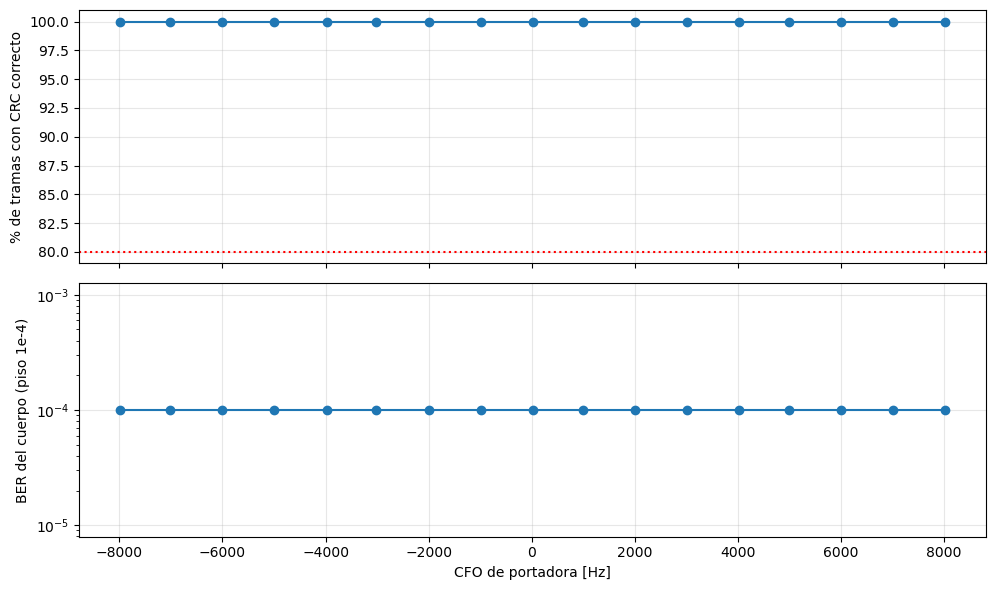

In [11]:
# ============================================================
# PASO 3d - Tolerancia al CFO con silencio entre ranuras (evita que el squelch se bloquee con ranuras adyacentes continuas)
# ============================================================
A_CFO       = 3000                                      # amplitud del DAC (nivel ~325)
OFFSETS_CFO = list(range(-8000, 8001, 1000))             # offset que se le pide al TX (Hz)
N_LECT_CFO  = 4                                         # lecturas de bits por offset
HUECO_BITS  = 0                                        # silencio que sigue a cada ranura (bits); 0 = ranuras adyacentes continuas
SEP_BITS    = 255 + HUECO_BITS                          # separacion de las tramas en el flujo demodulado (la ranura pierde 1 bit)

def ranura_n(words, nbit, amplitud, pre_bits=8, post_bits=20):
    """Ranura AIS con su propio bits->muestras (nbit), seguida de HUECO_BITS de silencio."""
    largo = int(round((pre_bits + n_trama + post_bits) * nbit / TX_BURST_SAMPLES)) * TX_BURST_SAMPLES
    r = con_rampa(words[(-int(round(pre_bits * nbit)) + np.arange(largo)) % len(words)], amplitud)
    return np.concatenate([r, np.zeros(int(round(HUECO_BITS * nbit / TX_BURST_SAMPLES)) * TX_BURST_SAMPLES, dtype=r.dtype)])

def sesgo_dato_hz(bb, nbit, pre_bits=8, post_bits=20):
    """Frecuencia media de la ranura (con sus rampas) por el solo contenido de los datos, sin portadora: lo que se suma al CFO en la frecuencia media del IQ."""
    largo = int(round((pre_bits + n_trama + post_bits) * nbit / TX_BURST_SAMPLES)) * TX_BURST_SAMPLES
    z = np.asarray(bb, dtype=np.complex128)[(-int(round(pre_bits * nbit)) + np.arange(largo)) % len(bb)].copy()
    n_r = int(RAMPA_BITS / BAUD * FS); g = np.ones(largo); r = 0.5 - 0.5 * np.cos(np.pi * np.arange(n_r) / n_r); g[:n_r] = r; g[-n_r:] = r[::-1]
    z *= g
    return float(np.angle(np.sum(z[1:] * np.conj(z[:-1]))) / (2 * np.pi) * FS)

def leer_tramas(n_lect):
    tr, ber_c, act = [], [], []
    for _ in range(n_lect):
        v = ventana(0.05); act.append(v['act_pct']); rpio.vaciar_fifo(sock); bits = rpio.leer_bits_demodulados(sock, N_PAL)
        cuentas = sum(np.array_equal(t, BARCOS[0]['payload']) for t in buscar_tramas(bits)); minimo = max(1, (len(bits) - n_trama) // SEP_BITS); pf = perfil_flujo(bits)
        tr.append(cuentas); ber_c.append(float(np.mean(pf['seg'][1:])) if pf else float('nan'))
    return tr, (float(np.nanmean(ber_c)) if not all(np.isnan(ber_c)) else float('nan')), minimo, float(np.mean(act))

# --- 0) estabilidad del squelch con este patron: la actividad no debe caer a 0 con el tiempo desde la carga
cargar_tx(sock, armar_buffer([ranura_n(BARCOS[0]['words'], N_BIT, A_CFO)])); t0 = time.perf_counter(); act_t = []
while time.perf_counter() - t0 < 5.0:
    v = ventana(0.25); act_t.append((time.perf_counter() - t0, v['act_pct'], v['n_ev'], v['umb_a']))
print("Estabilidad del squelch (silencio de %d bits): t [s] / activo %% / eventos / umbral_alto" % HUECO_BITS)
print("  " + "  ".join(f"{t:.1f}:{a:.0f}%/{e}/{u}" for t, a, e, u in act_t[::2]))
chequeo(min(a for t, a, e, u in act_t[2:]) > 50, f"el squelch sigue detectando a los {act_t[-1][0]:.1f} s (actividad minima {min(a for t, a, e, u in act_t[2:]):.0f}%)")

# --- 1) comprobacion previa con la trama de siempre (offset 300): debe dar tramas completas con BER 0
cargar_tx(sock, armar_buffer([ranura_n(BARCOS[0]['words'], N_BIT, A_CFO)])); time.sleep(T_ASENTA_S)
tr, ber, minimo, act = leer_tramas(N_LECT_CFO)
print(f"Comprobacion previa (offset 300): activo {act:.0f}%, tramas por lectura {tr} (minimo {minimo}), BER del cuerpo {ber:.4f}")
chequeo(all(t >= 0.9 * minimo for t in tr) and ber < 0.001, "la ranura con silencio da tramas completas y BER 0")

# --- 2) barrido. El CFO de portadora es fc_adj - f_lo (el TX usa un numero entero de ciclos en el buffer y el NCO del receptor esta en f_lo): no se captura IQ
filas_cfo = []; sesgo = None
print(f"\nA_dac {A_CFO}. 'portad.' = fc_adj - f_lo; 'medido eq.' = portad. + sesgo del contenido de la trama (lo que vera la frecuencia media del IQ)\n")
print(f"{'pedido':>7} {'portad.':>8} {'medido eq.':>10} {'activo%':>8}   {'tramas ok por lectura':<26} {'minimo':>6} {'% tramas':>8} {'BER cuerpo':>10}")
for off in OFFSETS_CFO:
    words, fc_adj, N, bb, bits_k, payload_k = txlib.generar_senal_ais_prueba(np.random.RandomState(2024), FS, f_lo, off, SPS_TX, L_PULSO, BT, A_REF, TX_BURST_SAMPLES)
    nbit = len(words) / len(bits_k)
    if sesgo is None: sesgo = sesgo_dato_hz(bb, nbit); print(f"(sesgo del contenido de la trama de prueba: {sesgo:+.0f} Hz)")
    cargar_tx(sock, armar_buffer([ranura_n(words, nbit, A_CFO)])); time.sleep(T_ASENTA_S)
    tr, ber, minimo, act = leer_tramas(N_LECT_CFO)
    portad = fc_adj - f_lo; pct = 100 * min(1.0, float(np.mean(tr)) / minimo); estricto = all(t >= 0.9 * minimo for t in tr)
    filas_cfo.append([off, round(portad, 1), round(portad + sesgo, 1), round(act, 1), json.dumps(tr), minimo, int(estricto), round(pct, 1), round(ber, 5)])
    print(f"{off:7d} {portad:8.0f} {portad + sesgo:10.0f} {act:8.0f}   {str(tr):<26} {minimo:6d} {pct:8.0f} {ber:10.4f}" + ("" if estricto else "   <--"))
guardar_csv('tolerancia_cfo_silencio.csv', ['offset_pedido_hz', 'cfo_portadora_hz', 'cfo_medido_equivalente_hz', 'activo_pct', 'tramas_por_lectura', 'minimo', 'estricto', 'pct_tramas', 'ber_cuerpo'], filas_cfo)

F = np.array([[f[1], f[2], f[6], f[7]] for f in filas_cfo], float); F = F[np.argsort(F[:, 0])]; i0 = int(np.argmin(np.abs(F[:, 0])))
def ancho(ok):
    if not ok[i0]: return None
    lo = hi = i0
    while lo > 0 and ok[lo - 1]: lo -= 1
    while hi < len(F) - 1 and ok[hi + 1]: hi += 1
    return lo, hi
for nombre, ok in (("estricta (todas las lecturas >= 90% del minimo)", F[:, 2] > 0.5), ("laxa (promedio de tramas >= 80% del minimo)", F[:, 3] >= 80)):
    r = ancho(ok)
    print(f"\nVentana {nombre}: " + (f"CFO de portadora {F[r[0], 0]:+.0f} a {F[r[1], 0]:+.0f} Hz (medido eq. {F[r[0], 1]:+.0f} a {F[r[1], 1]:+.0f} Hz), ancho {F[r[1], 0] - F[r[0], 0]:.0f} Hz" + ("" if 0 < r[0] and r[1] < len(F) - 1 else "  [llego al borde del barrido: ampliar OFFSETS_CFO]") if r else "no hay con CFO ~ 0: revisar"))
actualizar_json('resultados.json', tolerancia_cfo_silencio=dict(a_dac=A_CFO, hueco_bits=HUECO_BITS, sesgo_dato_hz=sesgo, filas=[dict(zip(['offset', 'portadora', 'medido_eq', 'activo', 'tramas', 'minimo', 'estricto', 'pct', 'ber'], f)) for f in filas_cfo]))

fig, ax = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
x = F[:, 0]; ax[0].plot(x, F[:, 3], 'o-'); ax[0].axhline(80, color='r', ls=':'); ax[0].set_ylabel('% de tramas con CRC correcto'); ax[0].grid(alpha=0.3)
berc = np.array([f[8] for f in filas_cfo])[np.argsort([f[1] for f in filas_cfo])]; ax[1].semilogy(x, np.maximum(berc, 1e-4), 'o-'); ax[1].set_ylabel('BER del cuerpo (piso 1e-4)'); ax[1].set_xlabel('CFO de portadora [Hz]'); ax[1].grid(alpha=0.3)
plt.tight_layout(); guardar_figura('tolerancia_cfo_silencio.png'); plt.show()

## Paso 3e - Demodulador contra ruido

A_dac 2000, hueco 64 bits (actividad esperada sin ruido ~80%), 10 cargas por punto, ruido de 40 kHz de ancho

   CFO  Eb/N0  % tramas  activo%  eventos  umbral  recorte
     0     10         0       97     28.8       4   0.0000
     0     13         0       32     26.8     431   0.0000
     0     16        38       81      6.3      31   0.0000
     0     19        78       80      5.1      13   0.0000
     0     22       100       80      4.4      10   0.0000
     0     25       100       81      4.0       4   0.0000
     0     30       100       81      4.0       4   0.0000
     0    sin       100       79      4.0       4   0.0000
  3000     10         0       99     17.5       4   0.0000
  3000     13         6       99     34.6       4   0.0000
  3000     16        66       80      4.6      55   0.0000
  3000     19        84       80      5.0      25   0.0000
  3000     22       100       81      4.4      14   0.0000
  3000     25       100       81      4.7       9   0.0000
  300

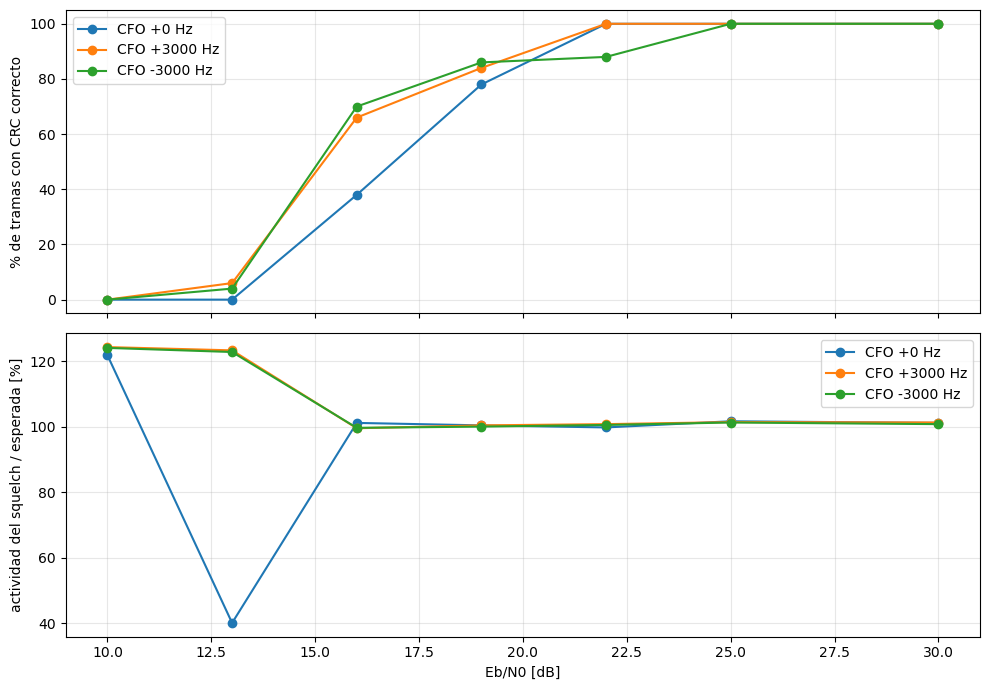

In [12]:
# ============================================================
# PASO 3e - Tramas contra Eb/N0 (ruido de banda limitada sumado en el DAC) y contra CFO
# ============================================================
A_RUIDO       = 2000                                    # amplitud de pico del DAC (nivel ~144)
EBN0_DB       = [10, 13, 16, 19, 22, 25, 30, None]      # Eb/N0 en dB; None = sin ruido
CFOS_PEDIDOS  = [0, 3000, -3000]                        # offset de portadora que se le pide al TX (Hz)
N_CARGAS      = 10                                      # cargas por punto; cada carga trae 2 realizaciones de ruido independientes
HUECO_RUIDO   = 64                                      # silencio tras cada ranura (bits); con 2 ranuras por buffer, 64 es el maximo que entra
B_RUIDO       = 40e3                                    # ancho de banda del ruido (Hz), centrado en la portadora
RB            = 9600.0                                  # velocidad de bits (Hz)
SEP_R         = 255 + HUECO_RUIDO                       # separacion de las tramas de una misma ranura en el flujo demodulado

def ruido_pasabanda(n, fs, fc, p_ruido, rng, b_ruido=B_RUIDO, fs_n=1e6, bloque=1 << 20):
    """Ruido gaussiano de banda limitada: b_ruido de ancho centrado en fc, n muestras a fs, potencia media p_ruido (cuentas^2 del DAC)."""
    nn = int(np.ceil(n * fs_n / fs)) + 2
    z = rng.randn(nn) + 1j * rng.randn(nn); Z = np.fft.fft(z); Z[np.abs(np.fft.fftfreq(nn, 1.0 / fs_n)) > b_ruido / 2] = 0
    zb = np.fft.ifft(Z); t_n = np.arange(nn) / fs_n; out = np.empty(n)
    for i0 in range(0, n, bloque):
        t = (i0 + np.arange(min(bloque, n - i0))) / fs; th = 2 * np.pi * fc * t
        out[i0:i0 + len(t)] = np.interp(t, t_n, zb.real) * np.cos(th) - np.interp(t, t_n, zb.imag) * np.sin(th)
    return out * np.sqrt(p_ruido / np.mean(out ** 2))

def ranura_r(words, nbit, amplitud, pre_bits=8, post_bits=20):
    """Ranura AIS seguida de HUECO_RUIDO bits de silencio (en cuentas del DAC con signo)."""
    largo = int(round((pre_bits + n_trama + post_bits) * nbit / TX_BURST_SAMPLES)) * TX_BURST_SAMPLES
    r = con_rampa(words[(-int(round(pre_bits * nbit)) + np.arange(largo)) % len(words)], amplitud)
    r = np.concatenate([r, np.zeros(int(round(HUECO_RUIDO * nbit / TX_BURST_SAMPLES)) * TX_BURST_SAMPLES, dtype=r.dtype)]).astype(np.int32) & 0x3FFF
    return np.where(r >= 0x2000, r - 0x4000, r).astype(np.float64)

def buffer_ruidoso(senal, fc, ebn0_db, rng):
    """senal: 2 ranuras seguidas (float, cuentas del DAC). Suma ruido de banda limitada con la potencia que da el Eb/N0 pedido (N0 unilateral = P_ruido / B_ruido)."""
    if ebn0_db is None: return armar_buffer([senal.astype(np.int32) & 0x3FFF]), None
    p_sig = A_RUIDO ** 2 / 2.0; p_ruido = p_sig / (10 ** (ebn0_db / 10.0) * RB) * B_RUIDO
    y = senal + ruido_pasabanda(len(senal), FS, fc, p_ruido, rng); recorte = float(np.mean((y > 8191) | (y < -8192)))
    return armar_buffer([np.clip(np.round(y), -8192, 8191).astype(np.int32) & 0x3FFF]), recorte

def leer_ruido():
    v = ventana(0.15); rpio.vaciar_fifo(sock); bits = rpio.leer_bits_demodulados(sock, N_PAL)
    cuentas = sum(np.array_equal(t, BARCOS[0]['payload']) for t in buscar_tramas(bits)); minimo = max(1, (len(bits) - n_trama) // SEP_R)
    return cuentas, minimo, v['act_pct'], v['n_ev'], v['umb_a']

rng_r = np.random.RandomState(12345); filas_r = []; duty = 100.0 * 256 / (256 + HUECO_RUIDO)
print(f"A_dac {A_RUIDO}, hueco {HUECO_RUIDO} bits (actividad esperada sin ruido ~{duty:.0f}%), {N_CARGAS} cargas por punto, ruido de {B_RUIDO / 1e3:.0f} kHz de ancho\n")
print(f"{'CFO':>6} {'Eb/N0':>6} {'% tramas':>9} {'activo%':>8} {'eventos':>8} {'umbral':>7} {'recorte':>8}")
for cfo in CFOS_PEDIDOS:
    words, fc_adj, N, bb, bits_k, payload_k = txlib.generar_senal_ais_prueba(np.random.RandomState(2024), FS, f_lo, cfo, SPS_TX, L_PULSO, BT, A_REF, TX_BURST_SAMPLES)
    nbit = len(words) / len(bits_k); r1 = ranura_r(words, nbit, A_RUIDO); senal = np.concatenate([r1, r1])
    for eb in EBN0_DB:
        pct, act, ev, um, rec = [], [], [], [], []
        for c in range(N_CARGAS if eb is not None else max(2, N_CARGAS // 5)):
            buf, recorte = buffer_ruidoso(senal, fc_adj, eb, rng_r); cargar_tx(sock, buf); time.sleep(T_ASENTA_S)
            cuentas, minimo, a, e, u = leer_ruido(); pct.append(100 * min(1.0, cuentas / minimo)); act.append(a); ev.append(e); um.append(u); rec.append(0.0 if recorte is None else recorte)
        filas_r.append([cfo, 'inf' if eb is None else eb, round(float(np.mean(pct)), 1), round(float(np.mean(act)), 1), round(float(np.mean(ev)), 1), round(float(np.mean(um)), 1), round(float(np.max(rec)), 5)])
        print(f"{cfo:6d} {('sin' if eb is None else str(eb)):>6} {filas_r[-1][2]:9.0f} {filas_r[-1][3]:8.0f} {filas_r[-1][4]:8.1f} {filas_r[-1][5]:7.0f} {filas_r[-1][6]:8.4f}")
guardar_csv('tramas_contra_ebn0.csv', ['cfo_pedido_hz', 'ebn0_db', 'pct_tramas', 'activo_pct', 'eventos', 'umbral_alto', 'recorte_max'], filas_r)

print("\nEb/N0 al que el % de tramas cruza el 50% (interpolado), y actividad del squelch respecto de la esperada en ese punto:")
fig, ax = plt.subplots(2, 1, figsize=(10, 7), sharex=True)
for cfo in CFOS_PEDIDOS:
    f = [x for x in filas_r if x[0] == cfo and x[1] != 'inf']; f.sort(key=lambda x: x[1]); e = np.array([x[1] for x in f], float); p = np.array([x[2] for x in f]); a = np.array([x[3] for x in f])
    ax[0].plot(e, p, 'o-', label=f'CFO {cfo:+d} Hz'); ax[1].plot(e, 100 * a / duty, 'o-', label=f'CFO {cfo:+d} Hz')
    ok = np.flatnonzero((p[:-1] < 50) & (p[1:] >= 50))
    if len(ok): i = ok[0]; e50 = e[i] + (50 - p[i]) * (e[i + 1] - e[i]) / (p[i + 1] - p[i]); print(f"  CFO {cfo:+5d} Hz: Eb/N0 = {e50:.1f} dB")
    else: print(f"  CFO {cfo:+5d} Hz: " + ("ya por encima del 50% en todo el barrido" if p[0] >= 50 else "no llega al 50% en el barrido"))
ax[0].set_ylabel('% de tramas con CRC correcto'); ax[1].set_ylabel('actividad del squelch / esperada [%]'); ax[1].set_xlabel('Eb/N0 [dB]')
for a_ in ax: a_.grid(alpha=0.3); a_.legend()
plt.tight_layout(); guardar_figura('tramas_contra_ebn0.png'); plt.show()
actualizar_json('resultados.json', ruido=dict(a_dac=A_RUIDO, hueco_bits=HUECO_RUIDO, b_ruido_hz=B_RUIDO, n_cargas=N_CARGAS, filas=[dict(zip(['cfo', 'ebn0', 'pct', 'activo', 'eventos', 'umbral', 'recorte'], f)) for f in filas_r]))

## Resumen y gráficos

Por cada fase: cuántas iteraciones tardó en converger (pico del barco más fuerte cerca de la referencia y todas las ráfagas detectables demodulando) y cuántas iteraciones demodularon en total.
Cada iteración es de ~1 s: no es el tiempo del AGC real, que corrige en milisegundos, sino cuántas actualizaciones de ganancia necesita.


=== escalones ===
fase                        iteraciones  iter. hasta converger  demodulan
inicial                               3                      2      3/3
sube 20 dB                            4                      3      4/4
baja 20 dB                            4                      4      2/4
sube 10 dB                            3                      2      3/3
Total: 12/14 iteraciones demodulan, 7/14 convergen
  guardado: datos_loopback\2026-11-11_122530\lazo_escalones.png


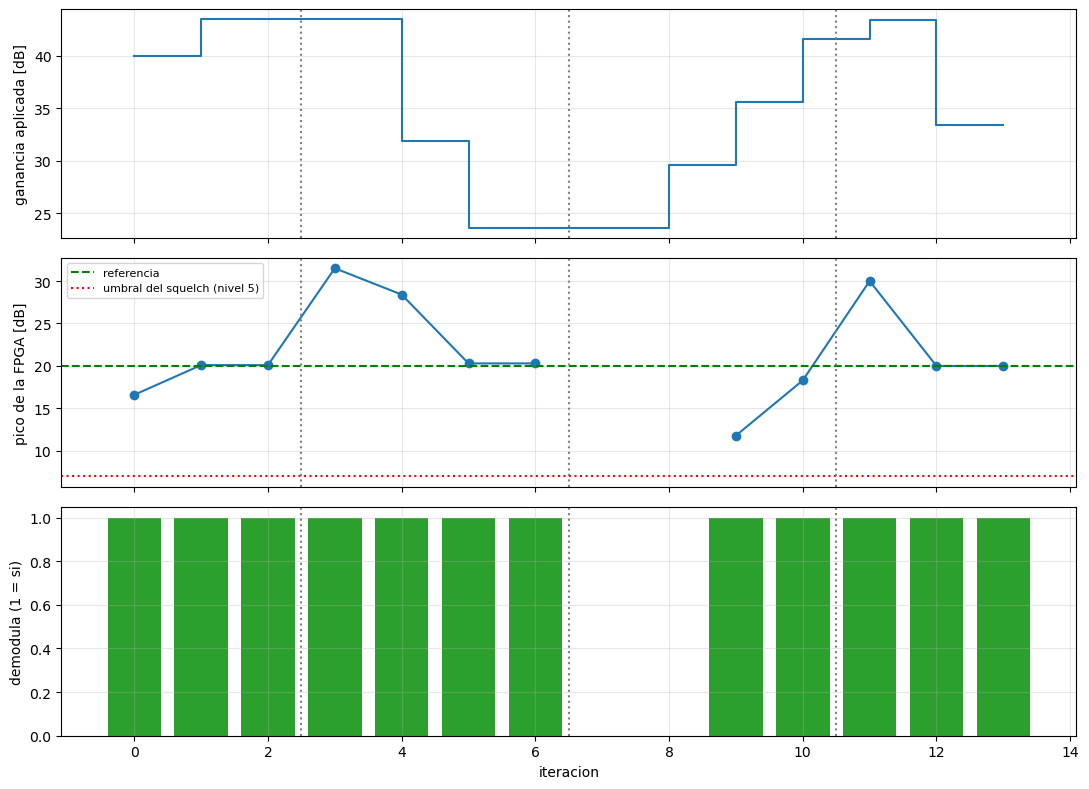

In [13]:
# ============================================================
# Resumen y graficos
# ============================================================
def resumen(nombre, filas):
    print(f"\n=== {nombre} ===")
    print(f"{'fase':<26} {'iteraciones':>12} {'iter. hasta converger':>22} {'demodulan':>10}")
    for fase in ESCENARIOS[nombre]:
        fs = [f for f in filas if f[1] == fase['nombre']]; conv = [k for k, f in enumerate(fs) if f[11]]
        print(f"{fase['nombre']:<26} {len(fs):12d} {(str(conv[0] + 1) if conv else 'no converge'):>22} {sum(f[10] for f in fs):>6d}/{len(fs)}")
    n = len(filas); print(f"Total: {sum(f[10] for f in filas)}/{n} iteraciones demodulan, {sum(f[11] for f in filas)}/{n} convergen")

for nombre, filas in RESULTADOS.items():
    resumen(nombre, filas)
    it = [f[0] for f in filas]; fig, ax = plt.subplots(3, 1, figsize=(11, 8), sharex=True)
    ax[0].step(it, [f[3] for f in filas], where='post'); ax[0].set_ylabel('ganancia aplicada [dB]'); ax[0].grid(alpha=0.3)
    ax[1].plot(it, [f[7] for f in filas], 'o-'); ax[1].axhline(CFG['ref_db'], color='g', ls='--', label='referencia'); ax[1].axhline(10 * math.log10(NIVEL_MIN), color='r', ls=':', label=f'umbral del squelch (nivel {NIVEL_MIN})')
    ax[1].set_ylabel('pico de la FPGA [dB]'); ax[1].legend(fontsize=8); ax[1].grid(alpha=0.3)
    ax[2].bar(it, [f[10] for f in filas], color=['tab:green' if f[10] else 'tab:red' for f in filas]); ax[2].set_ylabel('demodula (1 = si)'); ax[2].set_xlabel('iteracion'); ax[2].grid(alpha=0.3)
    for fase_i, f in enumerate(filas):
        if fase_i and f[1] != filas[fase_i - 1][1]:
            for a in ax: a.axvline(f[0] - 0.5, color='gray', ls=':')
    plt.tight_layout(); guardar_figura(f"lazo_{nombre.replace(' ', '_').replace('(', '').replace(')', '')}.png"); plt.show()

In [14]:
# ============================================================
# Limpieza
# ============================================================
rpio.tx_stop(sock); sock.close()
print("Sesion guardada en:", os.path.abspath(SESION_DIR))

Sesion guardada en: c:\Users\kirsh\OneDrive - UTN.BA\Facu\6-Proyecto Final\pavel\red-pitaya-notes\notebooks\datos_loopback\2026-11-11_122530
